## Introducción

Se desarrolla el esquema numérico para resolver la ecuación de difusión del propagador $P(\mathbf{r},t|\mathbf{r}_0)$ en geometría cilíndrica, primer paso para calcular la función de correlación $G(t)=\langle B(t)B(0)\rangle$ del campo dipolar en nano-NMR con centros NV.

## 1. Discretización de la ecuación completa

Partimos de la ecuación en coordenadas cilíndricas

$$\frac{\partial P}{\partial t}
=\frac{1}{\rho}\frac{\partial}{\partial\rho}\left(\rho\,D(z)\,\frac{\partial P}{\partial\rho}\right)
+\frac{\partial}{\partial z}\left(D(z)\,\frac{\partial P}{\partial z}\right),$$
para $\rho\in[0,R]$, $z\in[d,L+d]$.

---

### 1.1 Mallado

- **Uniforme** en $\rho$: $$\rho_i = i\,\Delta\rho,\quad i=0,1,\dots,N_r,\quad \Delta\rho = \frac{R}{N_r}.$$
- **No uniforme** en $z$: $$z_j=d+L\cdot \frac{\sinh{\left(\alpha_\mathrm{grid}\cdot\frac{j}{N_{z}-1}\right)}}{\sinh{\alpha_\mathrm{grid}}},\quad j\in\left[0,N_{z}-1\right]$$

Denotamos los pasos locales por $\Delta z_j = z_{j+1}-z_j$.

Definimos $$P_{i,j}^n \approx P(\rho_i,z_j,t^n),\qquad t^n=n\,\Delta t.$$

---

### 1.2 Derivadas espaciales

#### 1.2.1 Dirección radial $\rho$

Usamos diferencias conservativas en la forma  $$\frac1\rho\partial_\rho(\rho\,D\partial_\rho P).$$

Para $i=1,\dots,N_r-1$:

$$\begin{aligned}
  \partial_\rho P\big|_{i+\frac12,j}&\approx \frac{P_{i+1,j}^n - P_{i,j}^n}{\Delta\rho},\\
  (\rho\,D\,\partial_\rho P)_{i+\frac12,j}&\approx \rho_{i+\frac12}\,D(z_j)\,\frac{P_{i+1,j}^n - P_{i,j}^n}{\Delta\rho},\\
  \frac{1}{\rho_i}\frac{(\rho\,D\,\partial_\rho P)_{i+\frac12,j}-(\rho\,D\,\partial_\rho P)_{i-\frac12,j}}{\Delta\rho}&\approx \frac{1}{\rho_i\,\Delta\rho^2}\left[\rho_{i+\frac12}D_j\,(P_{i+1,j}^n - P_{i,j}^n)-\rho_{i-\frac12}D_j\,(P_{i,j}^n - P_{i-1,j}^n)\right].
\end{aligned}$$

En el **eje** $i=0$ imponemos simetría Neumann: $$\partial_\rho P|_{0,j}=0\implies P_{1,j}=P_{0,j}.$$

En la **pared** \(i=N_r\) (ρ=R) aplicamos Robin: $$D\,\frac{P_{N_r,j}-P_{N_r-1,j}}{\Delta\rho}+\kappa\,P_{N_r,j}=0.$$

---

#### 1.2.2 Dirección axial $z$

Para cada $i$ fijo, en $j=1,\dots,N_z-1$:

$$\begin{aligned}
\partial_zP\big|_{i,j+\frac12}&\approx \frac{P_{i,j+1}^n - P_{i,j}^n}{\Delta z_j},\\
(D\,\partial_zP)_{i,j+\frac12}&\approx D\!\bigl(z_{j+\tfrac12}\bigr)\,\frac{P_{i,j+1}^n - P_{i,j}^n}{\Delta z_j},\\
\frac{(D\,\partial_zP)_{i,j+\tfrac12} -(D\,\partial_zP)_{i,j-\tfrac12}}{\Delta z_j}&\approx \frac{1}{\Delta z_j}\left[D_{j+\frac12}\,(P_{i,j+1}^n - P_{i,j}^n)/\Delta z_j-D_{j-\frac12}\,(P_{i,j}^n - P_{i,j-1}^n)/\Delta z_{j-1}\right].
\end{aligned}$$

En los **bordes** $j=0$ (superficie $z=d$) y $j=N_z$ (tope $z=L+d$) imponemos Robin:

$$\begin{cases}
  D\,\partial_zP - \kappa P =0\quad(j=0),\\
  D\,\partial_zP + \kappa P =0\quad(j=N_z).
\end{cases}$$

---

### 1.3 Esquema en el tiempo: Crank–Nicolson

$$\frac{P_{i,j}^{n+1}-P_{i,j}^n}{\Delta t}=\frac12\left[L_{i,j}(P^n)+L_{i,j}(P^{n+1})\right],$$

donde $L_{i,j}$ es la suma de los términos radiales y axiales discretos anteriores. En forma matricial:

$$A\,\mathbf{P}^{n+1} = B\,\mathbf{P}^n,\quad A=I-\tfrac{\Delta t}{2}L,\quad B=I+\tfrac{\Delta t}{2}L.$$

---

### 1.4 Integral de correlación

Para la función $K(\rho,z)=\dfrac{3\cos^2\theta-1}{r^3}=\dfrac{2z^2-\rho^2}{(\rho^2+z^2)^{5/2}}$, la correlación se aproxima en **centros de celda** $(\rho_{i+½},z_{j+½})$ como

$$G^n \;\propto\; K(\rho_{i_0+1/2},z_{j_0+1/2})
\sum_{i=0}^{N_r-1}\sum_{j=0}^{N_z-1}
K(\rho_{i+1/2},z_{j+1/2})\;P_{i,j}^n\;\left(\rho_{i+1/2}\,\Delta\rho\,\Delta z_j\right).$$

Con esto disponemos de la discretización completa para implementar el esquema FD+CN.

In [1]:
import numpy as np
import scipy.sparse as sp
import scipy.sparse.linalg as spla
import matplotlib.pyplot as plt

In [2]:
# Parámetros físicos
d = 15.0 # [nm]
L = R = 100*d # [nm]
kappa = 0.0 # coef. Robin [nm/μs]
r0, z0 = 0.0, d

# Discretización temporal
times = np.logspace(-4, 7)
T = times[-1]  # [μs]
Nt = len(times)
dt = np.diff(times)

In [3]:
Nr, Nz    = 5000, 10000

# Mallado uniforme en rho
r_edges   = np.linspace(0, R, Nr+1)              # bordes
r_cent    = 0.5*(r_edges[:-1] + r_edges[1:])     # centros
dr        = r_edges[1] - r_edges[0]

# Mallado hiperbólico en z
alpha     = 2.0
j_idx     = np.arange(Nz+1)
z_edges   = d + L * np.sinh(alpha*j_idx/Nz) / np.sinh(alpha)  # bordes
dz_mid    = np.diff(z_edges)                                   # Δz en cada celda
z_cent    = 0.5*(z_edges[:-1] + z_edges[1:])                    # centros

# Número total de incógnitas
N = (Nr+1)*(Nz+1)

In [4]:
D0, Ds    = 2e3, 2e1    # nm^2/μs
lambda_p  = 0.75/d
delta     = 2*d/3
z_c       = 0.75*L

def D_of_z(z):
    S = 0.5*(1 + np.tanh((z - (z_c + d))/delta))
    return Ds + (D0-Ds)*((1 - np.exp(-lambda_p*(z-d)))*(1-S) + S)

# Values at nodes and centers
Dz_nodes = D_of_z(z_edges)                  # length Nz+1
Dz_mid   = D_of_z(z_cent)                   # length Nz

In [5]:
def idx(i, j):
    return i*(Nz+1) + j

In [6]:
L_mat = sp.lil_matrix((N, N))

for i in range(Nr+1):
    rho_i = r_edges[i] + 1e-16  # evitar cero absoluto
    for j in range(Nz+1):
        n = idx(i, j)

        # 1) Superficie z=d (j=0): Robin D·∂zP - κ P = 0
        if j == 0:
            Dp = 0.5*(Dz_nodes[0] + Dz_nodes[1])
            dz0 = dz_mid[0]
            # -Dp*(P_{i,1} - P_{i,0})/dz0 + κ P_{i,0} = 0
            L_mat[n, idx(i,1)] = -Dp/dz0
            L_mat[n, n]        =  Dp/dz0 + kappa
            continue

        # 2) Borde superior z=L+d (j=Nz): Robin D·∂zP + κ P = 0
        if j == Nz:
            Dm = 0.5*(Dz_nodes[-1] + Dz_nodes[-2])
            dzN = dz_mid[-1]
            # +Dm*(P_{i,Nz} - P_{i,Nz-1})/dzN + κ P_{i,Nz} = 0
            L_mat[n, idx(i,Nz-1)] = -Dm/dzN
            L_mat[n, n]           =  Dm/dzN + kappa
            continue

        # 3) Pared lateral ρ=R (i=Nr): Robin D·∂ρP + κ P = 0
        if i == Nr:
            Dm = Dz_mid[j-1] if j>0 else Dz_mid[0]
            # +Dm*(P_{Nr,j} - P_{Nr-1,j})/dr + κ P_{Nr,j} = 0
            L_mat[n, idx(Nr-1,j)] = -Dm/dr
            L_mat[n, n]           =  Dm/dr + kappa
            continue

        # 4) Eje ρ=0 (i=0): Neumann ∂ρP = 0 ⇒ P_{1,j} = P_{0,j}
        if i == 0:
            L_mat[n, idx(0,  j)] =  1.0
            L_mat[n, idx(1,  j)] = -1.0
            continue

        # 5) Interior: stencil conservativo 5 puntos
        # --- coeficientes radiales ---
        D_r = Dz_mid[j-1] if j>0 else Dz_mid[0]
        a_r_p = (rho_i + dr/2)*D_r/(dr**2)
        a_r_m = (rho_i - dr/2)*D_r/(dr**2)

        # --- coeficientes axiales ---
        D_zp = 0.5*(Dz_mid[j] + (Dz_mid[j+1] if j+1<Nz else Dz_mid[j]))
        D_zm = 0.5*(Dz_mid[j] + (Dz_mid[j-1] if j-1>=0  else Dz_mid[j]))
        a_z_p = D_zp/(dz_mid[j]  **2)
        a_z_m = D_zm/(dz_mid[j-1]**2) if j>0 else a_z_p

        # --- diagonal (conservación) ---
        diag = -(a_r_p + a_r_m + a_z_p + a_z_m)

        # Llenar la fila n
        L_mat[n, idx(i+1, j)] = a_r_p
        L_mat[n, idx(i-1, j)] = a_r_m
        L_mat[n, idx(i,   j+1)] = a_z_p
        L_mat[n, idx(i,   j-1)] = a_z_m
        L_mat[n, n]            = diag

# Convertir a CSR
L_mat = L_mat.tocsr()

KeyboardInterrupt: 

In [ ]:
# 1) Test dimensiones
print("L_mat.shape:", L_mat.shape)
print("nnz:", L_mat.nnz)

# 2) Test Neumann en el eje ρ=0 (i=0)
#    Cada fila n=idx(0,j) debe tener [1, -1] → suma 0
rows_i0 = [idx(0,j) for j in range(Nz+1)]
# extrae cada fila como array denso de sus valores y suma:
sums_i0 = []
for n in rows_i0:
    data = L_mat.data[L_mat.indptr[n]:L_mat.indptr[n+1]]
    sums_i0.append(np.sum(data))
print("Max |suma filas eje| (debe ser 0):", np.max(np.abs(sums_i0)))

# 3) Test Robin en ρ=R (i=Nr)
j_test = Nz//2
n_robin = idx(Nr, j_test)
cols_robin = L_mat.indices[L_mat.indptr[n_robin]:L_mat.indptr[n_robin+1]]
data_robin = L_mat.data   [L_mat.indptr[n_robin]:L_mat.indptr[n_robin+1]]
print(f"\nRobin lateral en (i={Nr}, j={j_test}):")
for c, v in zip(cols_robin, data_robin):
    print(f"  L[{n_robin},{c}] = {v:.6g}")
print("Suma fila (debe ser kappa):", np.sum(data_robin))

# 4) Test Robin en z=d (j=0)
i_test = Nr//3
n_robin_z0 = idx(i_test, 0)
data_z0 = L_mat.data[L_mat.indptr[n_robin_z0]:L_mat.indptr[n_robin_z0+1]]
print(f"\nRobin en z=d (i={i_test}, j=0): suma fila =", np.sum(data_z0))

# 5) Test interior stencil
i_int, j_int = Nr//2, Nz//2
n_int = idx(i_int, j_int)
cols_int = L_mat.indices[L_mat.indptr[n_int]:L_mat.indptr[n_int+1]]
data_int = L_mat.data   [L_mat.indptr[n_int]:L_mat.indptr[n_int+1]]
print(f"\nInterior en (i={i_int}, j={j_int}):")
print("  cols:", cols_int)
print("  data:", np.round(data_int, 6))
print("  número de entradas:", len(data_int))
row_sums = L_mat.sum(axis=1).A.flatten()
print("Máx |suma filas|:", np.max(np.abs(row_sums)))

L_mat.shape: (50015001, 50015001)
nnz: 249985005
Max |suma filas eje| (debe ser 0): 0.0

Robin lateral en (i=5000, j=5000):
  L[50010000,49999999] = -6666.67
  L[50010000,50010000] = 6666.67
Suma fila (debe ser kappa): 0.0

Robin en z=d (i=1666, j=0): suma fila = 0.0

Interior en (i=2500, j=5000):
  cols: [24997499 25007499 25007500 25007501 25017501]
  data: [ 16663333.332871    122782.952741 -33578861.839276    122745.554126
  16669999.999538]
  número de entradas: 5
Máx |suma filas|: 1.862645149230957e-08


In [ ]:
# Cell 6: Preparar identity y precondicionador Jacobi
I    = sp.eye(N)
diagA= (I + 0).diagonal()  # dummy just to define variable
# (we will build A_mat inside loop)
M_op = None  # idem

In [ ]:
# Condición inicial
# Encontrar índices más cercanos a r0, z0 en la malla
i0 = np.argmin(np.abs(r_cent - r0))
j0 = np.argmin(np.abs(z_cent - z0))
P_n = np.zeros(N)
r0 = r_cent[i0]
P_n[idx(i0,j0)] = 1 / (2 * np.pi * r0 * dr * dz_mid[j0])

In [ ]:
# precomputar kernel fuente y kernel espacial
# Kernel dipolar: f = (3cos^2(theta) - 1)/r^3 con cos(theta)=z/r, r^2=rho^2+z^2,
# es decir f = (3z^2 - r^2)/r^5 = (2z^2 - rho^2)/(rho^2+z^2)^{5/2}.
# (Antes: 3z^2 - rho^2; la resta va contra r^2, no contra rho^2.)
K_src = (2*z0**2 - r0**2)/(r0**2 + z0**2)**2.5
R_mid, Z_mid = np.meshgrid(r_cent, z_cent, indexing='ij')
K_mid = (2*Z_mid**2 - R_mid**2)/(R_mid**2 + Z_mid**2)**2.5
vol_mid = np.outer(r_cent*dr, dz_mid)
G = np.zeros(Nt)

In [ ]:
P_full = P_n.reshape((Nr+1, Nz+1))
P_mid  = P_full[:-1,:-1]
masa_0 = np.sum(P_mid * vol_mid)
print("Masa inicial:", masa_0)

Masa inicial: 0.15915494309189532


In [ ]:
# Cell 8: Bucle Crank–Nicolson con Δt variable
mass=[masa_0]
G[0] = K_src * np.sum(K_mid * P_mid * vol_mid)
for k in range(Nt-1):
    dtk = times[k+1] - times[k]
    # montar A_mat, B_mat
    A_mat = I - L_mat*(dtk/2) + I*1e-12
    B_mat = I + L_mat*(dtk/2)
    # actualizar precondicionador
    diagA = A_mat.diagonal()
    M_op   = spla.LinearOperator((N,N), matvec=lambda x: x/diagA)
    # RHS y solver
    b       = B_mat.dot(P_n)
    P_np1, info = spla.gmres(A_mat, b, M=M_op, rtol=1e-6, maxiter=500)
    if info != 0:
        print(f"⚠️ Paso {k} no convergió (info={info}); deteniendo")
        break
    P_n = P_np1
    # correlación
    P_full = P_n.reshape((Nr+1, Nz+1))
    P_mid  = P_full[:-1, :-1]
    m = np.sum(P_mid * vol_mid)
    mass.append(m)
    G[k]   = K_src * np.sum(K_mid * P_mid * vol_mid)

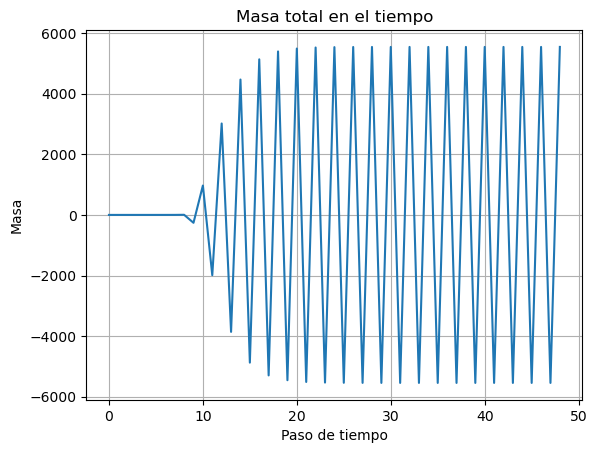

In [ ]:
plt.plot(mass)
plt.title("Masa total en el tiempo")
plt.xlabel("Paso de tiempo")
plt.ylabel("Masa")
plt.grid()
plt.show()

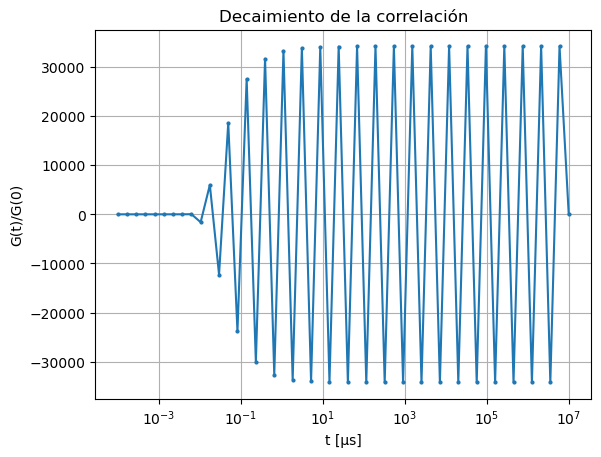

In [ ]:
# Calcular G[Nt] y graficar
# el último punto aún no se calculó dentro del bucle
P_full = P_n.reshape((Nr+1, Nz+1))
P_mid  = P_full[:-1, :-1]
# G[Nt]  = K_src * np.sum(K_mid * P_mid * vol_mid)

G_norm = G / G[0]
plt.figure()
plt.semilogx(times[:Nt+1], G_norm, '-o', markersize=2)
plt.xlabel('t [μs]')
plt.ylabel('G(t)/G(0)')
plt.title('Decaimiento de la correlación')
plt.grid(True)
plt.show()

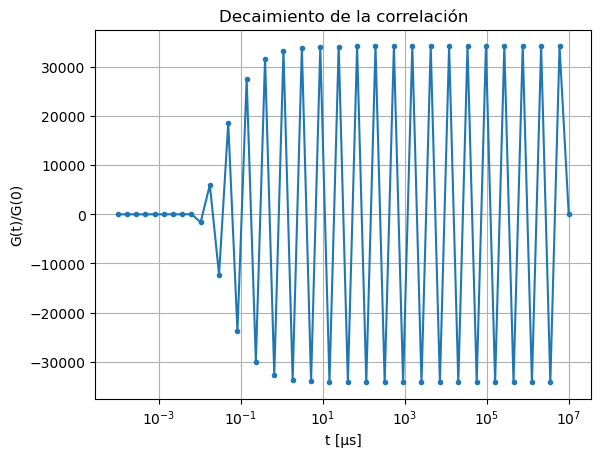

In [ ]:
# Visualización de G(t)
G_norm = G / G[0]
plt.figure()
plt.semilogx(times[:len(G_norm)], G_norm, '-o', markersize=3)
plt.xlabel('t [μs]')
plt.ylabel('G(t)/G(0)')
plt.title('Decaimiento de la correlación')
plt.grid(True)
plt.show()

## Conclusiones

Este cuaderno documenta el esquema de diferencias finitas con Crank–Nicolson para la ecuación de difusión cilíndrica 2D $(\rho, z)$ como alternativa a FEniCS, usando únicamente NumPy y SciPy.

Los puntos clave de la implementación son:

- **Operador conservativo**: diferencias centradas con promedio armónico de $D$ en las interfases garantiza conservación local de la probabilidad.
- **Malla adaptativa**: uniforme en $\rho$ e hiperbólica (sinh) en $z$, concentrando resolución en la zona de gradientes de $D(z)$ cerca de $z = d$.
- **Condiciones de contorno Robin**: implementadas con nodos fantasma para simetría axial en $\rho = 0$, Robin en $\rho = R$ y en $z = d$ y $z = L+d$.
- **Crank–Nicolson**: sistema lineal $A\mathbf{P}^{n+1} = B\mathbf{P}^n$ resuelto con GMRES + precondicionador Jacobi.
- **Limitación de memoria**: la malla $(N_r, N_z) = (5000, 10000)$ requiere $\sim 1.86\,\text{GiB}$ para el array disperso, excediendo la RAM disponible. Para producción se debe usar una malla más coarse o FEniCS con AMG.

Este cuaderno sirve como demostración del esquema numérico y como base matemática de la implementación FEniCS documentada en `SoluciónP.ipynb`.